# 13 — Probability Calibration and Threshold Optimization

[Previous](./12_Ensembling.ipynb) | [Repository guide](../README.md) | [Next](./14_Interpretation_and_Error_Analysis.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** make predicted probabilities more trustworthy, then choose a classification threshold that matches the competition’s F1 metric.

We compare the tuned **MLP** with Notebook 12’s winning **equal soft-voting ensemble**. The test data remains untouched.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


## 1. Two different questions

### Calibration

If a model gives `0.70` to 100 similar penalties, a well-calibrated model should see about 70 scored penalties.

### Threshold

The threshold converts a probability into a class:

- probability at least the threshold → `1` (scored);
- probability below the threshold → `0` (missed).

Calibration changes the **meaning of probabilities**. Threshold optimization changes the **decision rule**. A model can rank rows well but still need either or both.


In [1]:
from time import perf_counter
import hashlib
import json
import warnings

# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    brier_score_loss,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", message="X does not have valid feature names")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

fingerprint_values = pd.util.hash_pandas_object(
    train.sort_index(axis=1), index=True
).values.tobytes()
dataset_fingerprint = hashlib.sha256(fingerprint_values).hexdigest()[:12]

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Dataset fingerprint: {dataset_fingerprint}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
Dataset fingerprint: 3bc8d73b8f62


## 2. Freeze the experiment

We keep the same:

- engineered features and preprocessing;
- tuned base models;
- five outer validation folds;
- original class balance;
- F1 as the classification target.

Only the probability mapping and threshold change.


In [4]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result


X = add_engineered_features(train.drop(columns=[TARGET] + ID_COLUMNS))
y = train[TARGET].astype(int)
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y))

print(f"Model inputs: {X.shape[1]} columns before one-hot encoding")
print(f"Numerical: {len(numerical_columns)} | Categorical: {len(categorical_columns)} | Folds: {len(folds)}")

Model inputs: 49 columns before one-hot encoding
Numerical: 44 | Categorical: 5 | Folds: 5


In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ], sparse_threshold=0)

In [6]:
base_models = {
    "CatBoost": CatBoostClassifier(
        iterations=300,
        learning_rate=0.025,
        depth=8,
        l2_leaf_reg=5,
        random_strength=0.5,
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=600,
        learning_rate=0.025,
        num_leaves=15,
        max_depth=8,
        min_child_samples=10,
        subsample=1.0,
        subsample_freq=1,
        colsample_bytree=0.75,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    ),
    "Multilayer perceptron": MLPClassifier(
        hidden_layer_sizes=(96, 48),
        activation="tanh",
        learning_rate_init=0.003,
        batch_size=256,
        alpha=0.01,
        max_iter=250,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
}

base_summary = pd.DataFrame([
    ["CatBoost", "ordered boosted trees", "strong nonlinear interactions"],
    ["LightGBM", "leaf-wise boosted trees", "fast alternative tree rules"],
    ["Multilayer perceptron", "layers of nonlinear weights", "different learning mechanism"],
], columns=["base model", "how it learns", "why it may add diversity"])
display(base_summary.style.hide(axis="index"))


base model,how it learns,why it may add diversity
CatBoost,ordered boosted trees,strong nonlinear interactions
LightGBM,leaf-wise boosted trees,fast alternative tree rules
Multilayer perceptron,layers of nonlinear weights,different learning mechanism


## 3. Calibration methods

- **Raw:** keep the original probability.
- **Platt / sigmoid scaling:** fit a smooth logistic curve to the model’s log-odds.
- **Isotonic regression:** fit a flexible non-decreasing step function. It needs more calibration rows and can overfit small samples.
- **Beta calibration:** fit a logistic model using `log(p)` and `log(1-p)`. It can correct asymmetric probability distortion.
- **Cross-validated calibration:** fit the mapping without using the evaluated row. Our inner/outer procedure provides this protection.

`p` means the original predicted probability.


In [7]:
CALIBRATION_METHODS = ["Raw", "Platt sigmoid", "Isotonic", "Beta"]

def clipped(probabilities):
    return np.clip(np.asarray(probabilities, dtype=float), 1e-6, 1 - 1e-6)

def apply_calibration(method, train_scores, train_target, apply_scores):
    train_scores = clipped(train_scores)
    apply_scores = clipped(apply_scores)

    if method == "Raw":
        return train_scores, apply_scores

    if method == "Platt sigmoid":
        train_features = np.log(train_scores / (1 - train_scores)).reshape(-1, 1)
        apply_features = np.log(apply_scores / (1 - apply_scores)).reshape(-1, 1)
        calibrator = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
        calibrator.fit(train_features, train_target)
        return (
            calibrator.predict_proba(train_features)[:, 1],
            calibrator.predict_proba(apply_features)[:, 1],
        )

    if method == "Isotonic":
        calibrator = IsotonicRegression(out_of_bounds="clip")
        calibrator.fit(train_scores, train_target)
        return calibrator.predict(train_scores), calibrator.predict(apply_scores)

    if method == "Beta":
        train_features = np.column_stack([
            np.log(train_scores), np.log1p(-train_scores)
        ])
        apply_features = np.column_stack([
            np.log(apply_scores), np.log1p(-apply_scores)
        ])
        calibrator = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
        calibrator.fit(train_features, train_target)
        return (
            calibrator.predict_proba(train_features)[:, 1],
            calibrator.predict_proba(apply_features)[:, 1],
        )

    raise ValueError(f"Unknown calibration method: {method}")

def expected_calibration_error(target, probabilities, n_bins=10):
    probabilities = np.asarray(probabilities)
    target = np.asarray(target)
    edges = np.linspace(0, 1, n_bins + 1)
    bin_index = np.clip(np.digitize(probabilities, edges[1:-1]), 0, n_bins - 1)
    error = 0.0
    for current_bin in range(n_bins):
        mask = bin_index == current_bin
        if mask.any():
            error += mask.mean() * abs(probabilities[mask].mean() - target[mask].mean())
    return error


## 4. Base OOF probabilities

We first create ordinary five-fold OOF probabilities for the three tuned models.

The MLP probability is evaluated alone. The ensemble probability is the equal arithmetic mean of all three base probabilities.


In [8]:
folds = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y)
)

base_names = list(base_models)
base_oof_scores = {}

for name, estimator in base_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", estimator),
    ])
    start = perf_counter()
    base_oof_scores[name] = cross_val_predict(
        pipeline, X, y, cv=folds, method="predict_proba", n_jobs=1
    )[:, 1]
    elapsed = perf_counter() - start
    print(f"Finished {name} OOF probabilities in {elapsed:.1f}s")

base_matrix = np.column_stack([base_oof_scores[name] for name in base_names])
raw_source_scores = {
    "MLP": base_oof_scores["Multilayer perceptron"],
    "Equal soft ensemble": base_matrix.mean(axis=1),
}

for name, probabilities in raw_source_scores.items():
    print(
        f"{name}: F1@0.50 {f1_score(y, probabilities >= 0.50):.4f} | "
        f"Brier {brier_score_loss(y, probabilities):.4f}"
    )


Finished CatBoost OOF probabilities in 28.0s
Finished LightGBM OOF probabilities in 10.9s
Finished Multilayer perceptron OOF probabilities in 48.4s
MLP: F1@0.50 0.9471 | Brier 0.0357
Equal soft ensemble: F1@0.50 0.9495 | Brier 0.0330


## 5. Nested calibration and threshold selection

For each outer fold:

1. create four-fold inner OOF probabilities using only the outer-training rows;
2. fit each calibrator on those inner probabilities;
3. select the F1 threshold using those calibrated inner probabilities;
4. calibrate and classify the untouched outer fold.

This prevents both the calibration mapping and selected threshold from learning the evaluated label.


In [9]:
threshold_grid = np.round(np.arange(0.20, 0.801, 0.005), 3)

def threshold_statistics(target, probabilities):
    target = np.asarray(target, dtype=int)
    predictions = probabilities[:, None] >= threshold_grid[None, :]
    positives = target[:, None] == 1
    negatives = ~positives

    tp = np.sum(predictions & positives, axis=0)
    fp = np.sum(predictions & negatives, axis=0)
    fn = np.sum(~predictions & positives, axis=0)
    tn = np.sum(~predictions & negatives, axis=0)

    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp, dtype=float), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp, dtype=float), where=(tp + fn) > 0)
    specificity = np.divide(tn, tn + fp, out=np.zeros_like(tn, dtype=float), where=(tn + fp) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) > 0)

    return pd.DataFrame({
        "threshold": threshold_grid,
        "f1": f1,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "balanced_accuracy": (recall + specificity) / 2,
        "youden_j": recall + specificity - 1,
        "cost_fn2_fp1": 2 * fn + fp,
    })

def closest_to_half_best(table, score_column, maximize=True):
    best_value = table[score_column].max() if maximize else table[score_column].min()
    tied = table.loc[np.isclose(table[score_column], best_value)]
    return tied.iloc[np.argmin(abs(tied["threshold"].to_numpy() - 0.50))]

def select_objective_thresholds(table):
    choices = {
        "F1 optimal": closest_to_half_best(table, "f1"),
        "Balanced-accuracy optimal": closest_to_half_best(table, "balanced_accuracy"),
        "Youden J": closest_to_half_best(table, "youden_j"),
        "Cost FN=2, FP=1": closest_to_half_best(table, "cost_fn2_fp1", maximize=False),
    }

    precision_candidates = table.loc[table["precision"] >= 0.95]
    if precision_candidates.empty:
        choices["Precision at least 0.95"] = closest_to_half_best(table, "precision")
    else:
        choices["Precision at least 0.95"] = closest_to_half_best(
            precision_candidates, "recall"
        )

    recall_candidates = table.loc[table["recall"] >= 0.95]
    if recall_candidates.empty:
        choices["Recall at least 0.95"] = closest_to_half_best(table, "recall")
    else:
        choices["Recall at least 0.95"] = closest_to_half_best(
            recall_candidates, "precision"
        )
    return choices


In [10]:
source_names = list(raw_source_scores)
calibrated_oof = {
    source: {method: np.zeros(len(y), dtype=float) for method in CALIBRATION_METHODS}
    for source in source_names
}
nested_f1_predictions = {
    source: {method: np.zeros(len(y), dtype=int) for method in CALIBRATION_METHODS}
    for source in source_names
}
threshold_rows = []

objective_names = [
    "F1 optimal",
    "Balanced-accuracy optimal",
    "Youden J",
    "Cost FN=2, FP=1",
    "Precision at least 0.95",
    "Recall at least 0.95",
]
objective_predictions = {
    name: np.zeros(len(y), dtype=int) for name in objective_names
}
objective_threshold_rows = []

nested_start = perf_counter()
for outer_fold, (outer_train_index, outer_valid_index) in enumerate(folds, start=1):
    X_outer_train = X.iloc[outer_train_index]
    y_outer_train = y.iloc[outer_train_index]
    inner_folds = list(
        StratifiedKFold(
            n_splits=4, shuffle=True, random_state=RANDOM_STATE + outer_fold
        ).split(X_outer_train, y_outer_train)
    )

    inner_base = np.zeros((len(outer_train_index), len(base_names)))
    for model_index, name in enumerate(base_names):
        inner_pipeline = Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", base_models[name]),
        ])
        inner_base[:, model_index] = cross_val_predict(
            inner_pipeline,
            X_outer_train,
            y_outer_train,
            cv=inner_folds,
            method="predict_proba",
            n_jobs=1,
        )[:, 1]

    outer_base = base_matrix[outer_valid_index]
    inner_sources = {
        "MLP": inner_base[:, base_names.index("Multilayer perceptron")],
        "Equal soft ensemble": inner_base.mean(axis=1),
    }
    outer_sources = {
        "MLP": outer_base[:, base_names.index("Multilayer perceptron")],
        "Equal soft ensemble": outer_base.mean(axis=1),
    }

    for source in source_names:
        for method in CALIBRATION_METHODS:
            calibrated_train, calibrated_valid = apply_calibration(
                method,
                inner_sources[source],
                y_outer_train,
                outer_sources[source],
            )
            calibrated_oof[source][method][outer_valid_index] = calibrated_valid

            threshold_table = threshold_statistics(y_outer_train, calibrated_train)
            selected = closest_to_half_best(threshold_table, "f1")
            threshold = float(selected["threshold"])
            nested_f1_predictions[source][method][outer_valid_index] = (
                calibrated_valid >= threshold
            ).astype(int)
            threshold_rows.append({
                "outer fold": outer_fold,
                "source": source,
                "calibration": method,
                "selected threshold": threshold,
                "inner F1": selected["f1"],
            })

    # Demonstrate alternative threshold objectives on the raw winning ensemble.
    raw_ensemble_table = threshold_statistics(
        y_outer_train, inner_sources["Equal soft ensemble"]
    )
    choices = select_objective_thresholds(raw_ensemble_table)
    for objective, selected in choices.items():
        threshold = float(selected["threshold"])
        objective_predictions[objective][outer_valid_index] = (
            outer_sources["Equal soft ensemble"] >= threshold
        ).astype(int)
        objective_threshold_rows.append({
            "outer fold": outer_fold,
            "objective": objective,
            "selected threshold": threshold,
        })

    print(f"Finished outer fold {outer_fold}/5")

nested_seconds = perf_counter() - nested_start
threshold_history = pd.DataFrame(threshold_rows)
objective_threshold_history = pd.DataFrame(objective_threshold_rows)
print(f"Nested calibration and threshold selection completed in {nested_seconds:.1f}s")


Finished outer fold 1/5
Finished outer fold 2/5
Finished outer fold 3/5
Finished outer fold 4/5
Finished outer fold 5/5
Nested calibration and threshold selection completed in 280.2s


## 6. Did calibration improve the probabilities?

- **Log loss:** strongly penalizes confident wrong probabilities; lower is better.
- **Brier score:** mean squared error of the probability; lower is better.
- **ECE:** average gap between predicted probability and observed scoring rate across bins; lower is better.
- **ROC-AUC:** ranking quality. Smooth calibration should change probability meaning more than ranking.
- **Reliability diagram:** points on the diagonal mean predicted probability matches observed frequency.

F1 at `0.50` is shown, but calibration quality is judged mainly by log loss, Brier, and ECE.


In [11]:
calibration_rows = []
for source in source_names:
    for method in CALIBRATION_METHODS:
        probabilities = clipped(calibrated_oof[source][method])
        predictions = (probabilities >= 0.50).astype(int)
        calibration_rows.append({
            "source": source,
            "calibration": method,
            "log_loss": log_loss(y, probabilities),
            "brier": brier_score_loss(y, probabilities),
            "ece": expected_calibration_error(y, probabilities),
            "roc_auc": roc_auc_score(y, probabilities),
            "f1_at_0.50": f1_score(y, predictions),
        })

calibration_results = pd.DataFrame(calibration_rows).sort_values(
    ["brier", "log_loss"]
).reset_index(drop=True)
display(calibration_results.style.hide(axis="index").format(precision=4))


source,calibration,log_loss,brier,ece,roc_auc,f1_at_0.50
Equal soft ensemble,Isotonic,0.1070,0.0325,0.0027,0.9930,0.9491
Equal soft ensemble,Platt sigmoid,0.1065,0.0326,0.0048,0.9931,0.9495
Equal soft ensemble,Beta,0.1065,0.0326,0.0051,0.9931,0.9493
Equal soft ensemble,Raw,0.1132,0.0330,0.0170,0.9931,0.9495
MLP,Beta,0.1182,0.0352,0.0056,0.9914,0.9469
MLP,Platt sigmoid,0.1182,0.0352,0.0057,0.9914,0.9469
MLP,Isotonic,0.1193,0.0353,0.0045,0.9914,0.9468
MLP,Raw,0.1220,0.0357,0.0133,0.9914,0.9471


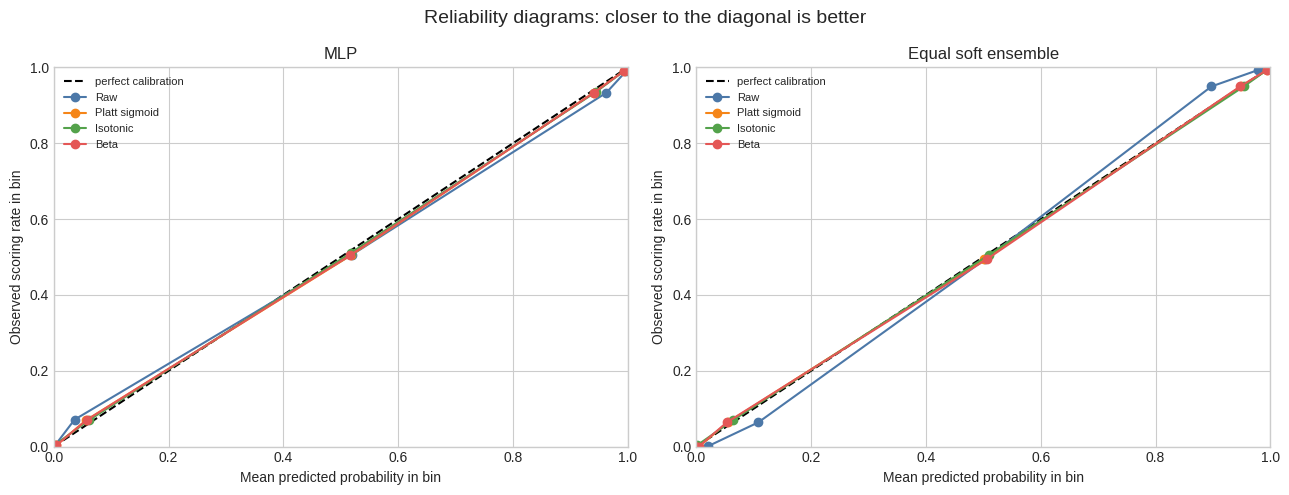

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
method_colors = {
    "Raw": "#4C78A8",
    "Platt sigmoid": "#F58518",
    "Isotonic": "#54A24B",
    "Beta": "#E45756",
}

for axis, source in zip(axes, source_names):
    axis.plot([0, 1], [0, 1], "--", color="black", label="perfect calibration")
    for method in CALIBRATION_METHODS:
        observed, predicted = calibration_curve(
            y, calibrated_oof[source][method], n_bins=10, strategy="quantile"
        )
        axis.plot(
            predicted, observed, marker="o",
            label=method, color=method_colors[method],
        )
    axis.set(
        title=source,
        xlabel="Mean predicted probability in bin",
        ylabel="Observed scoring rate in bin",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    axis.legend(fontsize=8)

fig.suptitle("Reliability diagrams: closer to the diagonal is better", fontsize=14)
plt.tight_layout()
plt.show()


## 7. Did a learned F1 threshold improve classification?

Each displayed optimized prediction uses the threshold selected inside its own outer-training fold.

Threshold stability matters: very different fold thresholds indicate an uncertain decision rule. The median fold threshold is a practical candidate for later final training.


In [13]:
threshold_result_rows = []
for source in source_names:
    for method in CALIBRATION_METHODS:
        probabilities = calibrated_oof[source][method]
        default_predictions = (probabilities >= 0.50).astype(int)
        optimized_predictions = nested_f1_predictions[source][method]
        selected_values = threshold_history.loc[
            threshold_history["source"].eq(source)
            & threshold_history["calibration"].eq(method),
            "selected threshold",
        ]
        threshold_result_rows.append({
            "source": source,
            "calibration": method,
            "f1_at_0.50": f1_score(y, default_predictions),
            "nested_f1_threshold": f1_score(y, optimized_predictions),
            "change": f1_score(y, optimized_predictions) - f1_score(y, default_predictions),
            "precision": precision_score(y, optimized_predictions),
            "recall": recall_score(y, optimized_predictions),
            "balanced_accuracy": balanced_accuracy_score(y, optimized_predictions),
            "median_threshold": selected_values.median(),
            "threshold_std": selected_values.std(ddof=1),
            "threshold_min": selected_values.min(),
            "threshold_max": selected_values.max(),
        })

threshold_results = pd.DataFrame(threshold_result_rows).sort_values(
    "nested_f1_threshold", ascending=False
).reset_index(drop=True)
display(threshold_results.style.hide(axis="index").format({
    "f1_at_0.50": "{:.4f}",
    "nested_f1_threshold": "{:.4f}",
    "change": "{:+.4f}",
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "balanced_accuracy": "{:.4f}",
    "median_threshold": "{:.3f}",
    "threshold_std": "{:.3f}",
    "threshold_min": "{:.3f}",
    "threshold_max": "{:.3f}",
}))


source,calibration,f1_at_0.50,nested_f1_threshold,change,precision,recall,balanced_accuracy,median_threshold,threshold_std,threshold_min,threshold_max
Equal soft ensemble,Isotonic,0.9491,0.9497,+0.0006,0.9490,0.9504,0.9543,0.500,0.011,0.480,0.500
Equal soft ensemble,Platt sigmoid,0.9495,0.9495,+0.0001,0.9489,0.9502,0.9542,0.495,0.026,0.465,0.525
Equal soft ensemble,Raw,0.9495,0.9494,-0.0001,0.9489,0.9498,0.9540,0.500,0.020,0.475,0.525
Equal soft ensemble,Beta,0.9493,0.9493,+0.0000,0.9487,0.9499,0.9539,0.500,0.033,0.465,0.550
MLP,Beta,0.9469,0.9469,+0.0001,0.9446,0.9492,0.9518,0.515,0.029,0.460,0.535
MLP,Isotonic,0.9468,0.9468,-0.0000,0.9451,0.9485,0.9517,0.500,0.009,0.480,0.500
MLP,Platt sigmoid,0.9469,0.9465,-0.0004,0.9456,0.9475,0.9514,0.530,0.036,0.465,0.555
MLP,Raw,0.9471,0.9464,-0.0007,0.9440,0.9489,0.9514,0.505,0.041,0.450,0.555


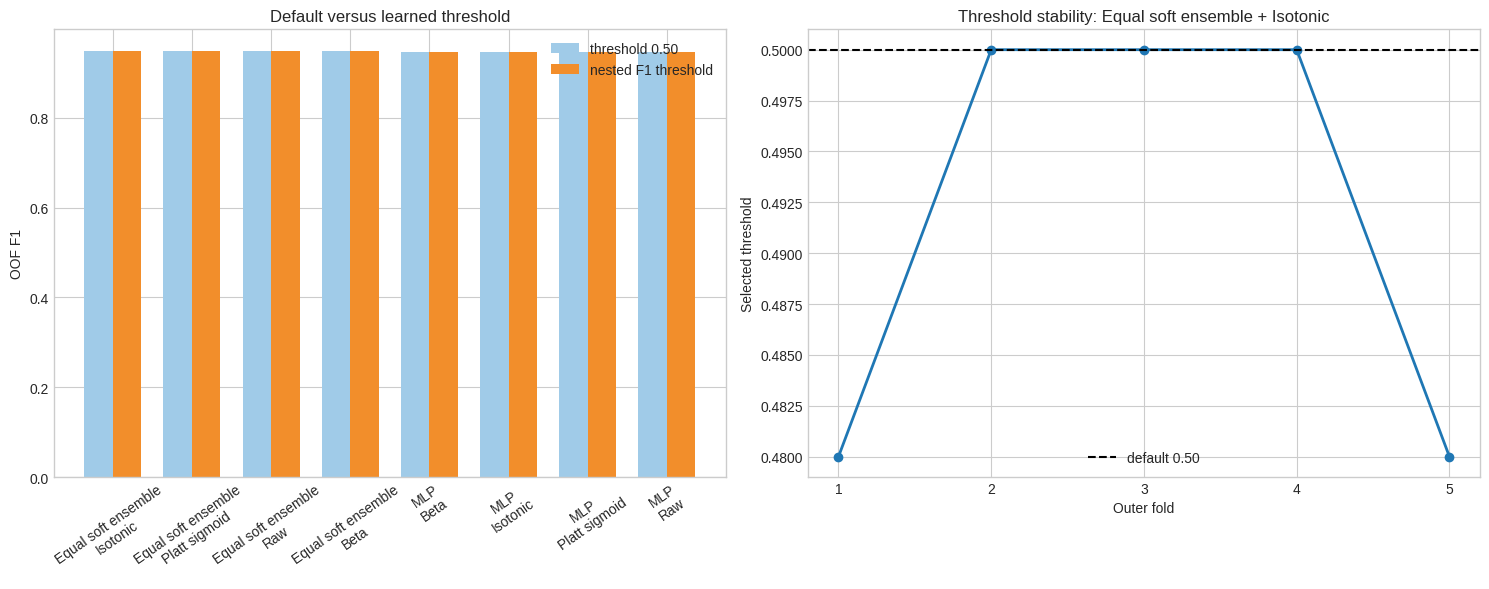

In [14]:
labels = threshold_results["source"] + "\n" + threshold_results["calibration"]
x = np.arange(len(threshold_results))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].bar(
    x - width / 2, threshold_results["f1_at_0.50"],
    width, label="threshold 0.50", color="#A0CBE8",
)
axes[0].bar(
    x + width / 2, threshold_results["nested_f1_threshold"],
    width, label="nested F1 threshold", color="#F28E2B",
)
axes[0].set(
    title="Default versus learned threshold",
    ylabel="OOF F1",
    xticks=x,
    xticklabels=labels,
)
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend()

best_threshold_row = threshold_results.iloc[0]
best_history = threshold_history.loc[
    threshold_history["source"].eq(best_threshold_row["source"])
    & threshold_history["calibration"].eq(best_threshold_row["calibration"])
]
axes[1].plot(
    best_history["outer fold"], best_history["selected threshold"],
    marker="o", linewidth=2,
)
axes[1].axhline(0.50, color="black", linestyle="--", label="default 0.50")
axes[1].set(
    title=f"Threshold stability: {best_threshold_row['source']} + {best_threshold_row['calibration']}",
    xlabel="Outer fold",
    ylabel="Selected threshold",
    xticks=best_history["outer fold"],
)
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Alternative threshold objectives

The best threshold depends on the real objective:

- **F1 optimal:** balances precision and recall through their harmonic mean.
- **Youden’s J:** `recall + specificity - 1`; balances the positive and negative classes.
- **Balanced-accuracy optimal:** average of recall and specificity. For binary classification it ranks thresholds exactly like Youden’s J.
- **Cost-sensitive:** here, one false negative costs twice one false positive.
- **Precision constrained:** require at least 0.95 precision, then maximize recall.
- **Recall constrained:** require at least 0.95 recall, then maximize precision.

**Specificity** is the fraction of actual misses correctly predicted as misses.


In [15]:
objective_rows = []
for objective, predictions in objective_predictions.items():
    values = objective_threshold_history.loc[
        objective_threshold_history["objective"].eq(objective),
        "selected threshold",
    ]
    objective_rows.append({
        "objective": objective,
        "f1": f1_score(y, predictions),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "median_threshold": values.median(),
        "threshold_std": values.std(ddof=1),
    })

objective_results = pd.DataFrame(objective_rows).sort_values("f1", ascending=False)
display(objective_results.style.hide(axis="index").format(precision=4))


objective,f1,precision,recall,balanced_accuracy,median_threshold,threshold_std
Recall at least 0.95,0.9497,0.9464,0.9531,0.9545,0.4850,0.0050
F1 optimal,0.9494,0.9489,0.9498,0.9540,0.5000,0.0198
Balanced-accuracy optimal,0.9492,0.9434,0.9551,0.9541,0.4750,0.0353
Youden J,0.9492,0.9434,0.9551,0.9541,0.4750,0.0353
Precision at least 0.95,0.9490,0.9506,0.9475,0.9536,0.5050,0.0067
"Cost FN=2, FP=1",0.9454,0.9201,0.9722,0.9516,0.3650,0.0260


### Concrete dataset example: probability buckets

Rows are grouped into ten equal-sized probability buckets for the best-calibrated source.

`mean predicted` should be close to `observed scoring rate`. The difference shows whether that bucket is overconfident or underconfident.


In [16]:
best_calibration = calibration_results.iloc[0]
best_calibrated_probabilities = calibrated_oof[
    best_calibration["source"]
][best_calibration["calibration"]]

bucket_frame = pd.DataFrame({
    "probability": best_calibrated_probabilities,
    "actual": y.to_numpy(),
})
bucket_frame["bucket"] = pd.qcut(
    bucket_frame["probability"], q=10, duplicates="drop"
)
bucket_summary = bucket_frame.groupby("bucket", observed=True).agg(
    rows=("actual", "size"),
    mean_predicted=("probability", "mean"),
    observed_scoring_rate=("actual", "mean"),
).reset_index()
bucket_summary["calibration_gap"] = (
    bucket_summary["mean_predicted"] - bucket_summary["observed_scoring_rate"]
)
display(bucket_summary.style.hide(axis="index").format({
    "mean_predicted": "{:.3f}",
    "observed_scoring_rate": "{:.3f}",
    "calibration_gap": "{:+.3f}",
}))


bucket,rows,mean_predicted,observed_scoring_rate,calibration_gap
"(-0.001, 0.00216]",8077,0.000,0.000,-0.000
"(0.00216, 0.18]",1991,0.065,0.070,-0.006
"(0.18, 0.857]",1938,0.510,0.506,+0.004
"(0.857, 0.988]",2039,0.954,0.949,+0.004
"(0.988, 1.0]",5955,0.998,0.998,+0.000


### Concrete dataset example: decisions changed by the threshold

The rows below are closest to the selected fold-specific thresholds. These are the cases most likely to change class when the threshold moves away from `0.50`.


In [17]:
best_threshold = threshold_results.iloc[0]
best_source = best_threshold["source"]
best_method = best_threshold["calibration"]
best_probabilities = calibrated_oof[best_source][best_method]
best_optimized_predictions = nested_f1_predictions[best_source][best_method]
best_default_predictions = (best_probabilities >= 0.50).astype(int)

fold_threshold_per_row = np.zeros(len(y), dtype=float)
for _, row in threshold_history.loc[
    threshold_history["source"].eq(best_source)
    & threshold_history["calibration"].eq(best_method)
].iterrows():
    valid_index = folds[int(row["outer fold"]) - 1][1]
    fold_threshold_per_row[valid_index] = row["selected threshold"]

changed = best_default_predictions != best_optimized_predictions
distance = np.abs(best_probabilities - fold_threshold_per_row)
priority = 10 * changed - distance
example_index = np.argsort(priority)[-8:][::-1]

decision_example = pd.DataFrame({
    "actual": y.iloc[example_index].to_numpy(),
    "calibrated probability": best_probabilities[example_index],
    "default threshold": 0.50,
    "fold-selected threshold": fold_threshold_per_row[example_index],
    "class at 0.50": best_default_predictions[example_index],
    "class after optimization": best_optimized_predictions[example_index],
}, index=train.iloc[example_index]["id"].rename("penalty id"))
display(decision_example.style.format(precision=3))


,actual,calibrated probability,default threshold,fold-selected threshold,class at 0.50,class after optimization
penalty id,,,,,,
17423,1,0.481,0.500,0.480,0,1
19591,1,0.481,0.500,0.480,0,1
13934,0,0.481,0.500,0.480,0,1
15041,0,0.481,0.500,0.480,0,1
15100,1,0.481,0.500,0.480,0,1
18912,1,0.481,0.500,0.480,0,1
11474,0,0.481,0.500,0.480,0,1
10631,1,0.481,0.500,0.480,0,1


## 9. Decision

Calibration is selected by probability quality, especially Brier score and log loss. Threshold selection is judged separately by nested OOF F1 and stability.

The selected pair remains validation evidence. Final training will fit one calibrator and one threshold using training-only OOF predictions.


In [18]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

best_calibration = calibration_results.iloc[0]
best_threshold = threshold_results.iloc[0]

print(
    f"Best calibration: {best_calibration['source']} + {best_calibration['calibration']} | "
    f"Brier {best_calibration['brier']:.4f} | Log loss {best_calibration['log_loss']:.4f}"
)
print(
    f"Best nested F1 decision: {best_threshold['source']} + {best_threshold['calibration']} | "
    f"F1 {best_threshold['nested_f1_threshold']:.4f}"
)
print(
    f"Recommended threshold candidate: median {best_threshold['median_threshold']:.3f} "
    f"(fold range {best_threshold['threshold_min']:.3f}–{best_threshold['threshold_max']:.3f})"
)

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)

calibration_results.to_csv(results_dir / "13_calibration_comparison.csv", index=False)
threshold_results.to_csv(results_dir / "13_threshold_comparison.csv", index=False)
threshold_history.to_csv(results_dir / "13_fold_thresholds.csv", index=False)
objective_results.to_csv(results_dir / "13_threshold_objectives.csv", index=False)

oof_export = pd.DataFrame({"id": train["id"], "actual": y})
for source in source_names:
    for method in CALIBRATION_METHODS:
        oof_export[f"{source} | {method}"] = calibrated_oof[source][method]
oof_export.to_csv(results_dir / "13_oof_calibrated_probabilities.csv", index=False)

decision = {
    "dataset_fingerprint": dataset_fingerprint,
    "best_calibration_source": best_calibration["source"],
    "best_calibration_method": best_calibration["calibration"],
    "best_threshold_source": best_threshold["source"],
    "best_threshold_calibration": best_threshold["calibration"],
    "nested_f1": float(best_threshold["nested_f1_threshold"]),
    "recommended_median_threshold": float(best_threshold["median_threshold"]),
}
with (results_dir / "13_calibration_threshold_decision.json").open("w", encoding="utf-8") as handle:
    json.dump(decision, handle, indent=2)

print(f"Saved calibration and threshold artifacts to: {results_dir}")


Best calibration: Equal soft ensemble + Isotonic | Brier 0.0325 | Log loss 0.1070
Best nested F1 decision: Equal soft ensemble + Isotonic | F1 0.9497
Recommended threshold candidate: median 0.500 (fold range 0.480–0.500)
Saved calibration and threshold artifacts to: /kaggle/working


## Why this decision is justified

**Technical evidence:** calibration is evaluated with log loss, Brier score, ECE, ROC-AUC, and reliability diagrams. Thresholds are selected inside inner folds and judged only on untouched outer folds.

**Theoretical reason:** calibration improves probability meaning, while threshold optimization aligns class decisions with the chosen objective. Keeping them separate prevents a higher F1 from being mistaken for better probability quality.
